<a href="https://colab.research.google.com/github/vicente-gonzalez-ruiz/medical_imaging/blob/main/notebooks/unet_n2n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Zero-Shot (Single Noisy Image) Self-Supervised Training
Here we implement a self-supervised strategy using ONLY a single noisy image (noisy_source). We will train the U-Net using a pixel-masking strategy: randomly masking out pixels in the input and calculating the loss only on those masked-out pixel locations compared to the original noisy pixels.


In [1]:
import urllib.request
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

In [2]:
# Define the U-Net (see https://arxiv.org/pdf/1803.04189) (see https://github.com/sashrika15/noise2noise/blob/master/unet.py)

class Unet(nn.Module):
    '''
    Unet architecture for n2n.
    No batch norm, dropout
    '''

    def __init__(self, in_channels=3, out_channels=3):
            """Initializes U-Net."""

            super(Unet, self).__init__()

            self._block1 = nn.Sequential(
                nn.Conv2d(in_channels, 48, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(48, 48, 3, padding=1),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2))

            self._block2 = nn.Sequential(
                nn.Conv2d(48, 48, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2))

            self._block3 = nn.Sequential(
                nn.Conv2d(48, 48, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.ConvTranspose2d(48, 48, 3, stride=2, padding=1, output_padding=1))

            self._block4 = nn.Sequential(
                nn.Conv2d(96, 96, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(96, 96, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.ConvTranspose2d(96, 96, 3, stride=2, padding=1, output_padding=1))

            self._block5 = nn.Sequential(
                nn.Conv2d(144, 96, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(96, 96, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.ConvTranspose2d(96, 96, 3, stride=2, padding=1, output_padding=1))

            self._block6 = nn.Sequential(
                nn.Conv2d(96 + in_channels, 64, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(64, 32, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(32, out_channels, 3, stride=1, padding=1),
                nn.LeakyReLU(0.1))


    def forward(self, x):

        #Encoder
        #print("X size = ", str(x.size()))
        pool1 = self._block1(x)
        #print(pool1.size())
        pool2 = self._block2(pool1)
        #print(pool2.size())
        pool3 = self._block2(pool2)
        #print(pool3.size())
        pool4 = self._block2(pool3)
        #print(pool4.size())
        pool5 = self._block2(pool4)
        #print(pool5.size())

        #Decoder
        upsample5 = self._block3(pool5)
        #print(upsample5.size())
        concat5 = torch.cat((upsample5, pool4), dim=1)
        #print(concat5.size())
        upsample4 = self._block4(concat5)
        #print(upsample4.size())
        concat4 = torch.cat((upsample4, pool3), dim=1)
        #print(concat4.size())
        upsample3 = self._block5(concat4)
        #print(upsample3.size())
        concat3 = torch.cat((upsample3, pool2), dim=1)
        #print(concat3.size())
        upsample2 = self._block5(concat3)
        #print(upsample2.size())
        concat2 = torch.cat((upsample2, pool1), dim=1)
        #print(concat2.size())
        upsample1 = self._block5(concat2)
        #print(upsample1.size())
        concat1 = torch.cat((upsample1, x), dim=1)
        #print(concat1.size())
        output = self._block6(concat1)
        #print(output.size())
        return output

    def summary(self):
        print('Unet summary: ')
        print(self._block1)
        print(self._block2)
        print(self._block3)
        print(self._block4)
        print(self._block5)
        print(self._block6)

Unet(in_channels=1, out_channels=1).summary()

Unet summary: 
Sequential(
  (0): Conv2d(1, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): ConvTranspose2d(48, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
)
Sequential(
  (0): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): ConvTranspose2d(96, 96, kernel_size=(3, 3), stride=(2, 2), pad

In [3]:
# Determine the "device"

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cpu')

In [6]:
# Configure the denoiser's training

denoiser = Unet(in_channels=1, out_channels=1).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(denoiser.parameters(), lr=0.001)
epochs = 10

In [4]:
# Load Lena

url = "https://www.hpca.ual.es/~vruiz/images/lena_512x512_gray.png"
with urllib.request.urlopen(url) as response:
    img_data = response.read()
    clean = Image.open(io.BytesIO(img_data)).convert('L')
clean = np.array(clean, dtype=np.uint8)

In [7]:
# Add noise

mean = 0
sigma = 25

# Ensure clean is treated as a numpy array for numpy-based noise creation
clean_np = clean.numpy() if isinstance(clean, torch.Tensor) else clean
gaussian_noise = np.random.normal(mean, sigma, clean_np.shape)
noisy = np.clip(clean_np + gaussian_noise, 0, 255).astype(np.uint8)

# Ensure clean_base is a PyTorch float tensor scaled to [0, 1]
clean_tensor = torch.from_numpy(clean_np) if isinstance(clean_np, np.ndarray) else clean
clean_base = clean_tensor.float() / 255.0

# Generate first independent noisy realization (noisy_source)
noise1 = torch.randn_like(clean_base) * (25.0 / 255.0)
noisy_source = torch.clamp(clean_base + noise1, 0.0, 1.0).unsqueeze(0).unsqueeze(0)

# Generate second independent noisy realization (noisy_target)
#noise2 = torch.randn_like(clean_base) * (25.0 / 255.0)
#noisy_target = torch.clamp(clean_base + noise2, 0.0, 1.0).unsqueeze(0).unsqueeze(0)

# 4. Create PyTorch Dataset and DataLoader
dataset = TensorDataset(noisy_source, noisy_target)
lena_loader = DataLoader(dataset, batch_size=1, shuffle=True)

# 5. Map the models and metrics to align with variables in the next cell's training loop
model_lena = denoiser
losses = []

# Prepare fixed noisy input scaled to [0, 1] for visual tracking
fixed_noisy_input = noisy_source.to(device)

In [10]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Define the tile size
tile_size = 32
img_size = 512

# Ensure noisy_source and noisy_target are available (each has shape [1, 1, 512, 512])
# We will extract 32x32 tiles
tiles_source = []
tiles_target = []

for i in range(0, img_size, tile_size):
    for j in range(0, img_size, tile_size):
        # Slice out 32x32 patches
        tile_src = noisy_source[:, :, i:i+tile_size, j:j+tile_size]
        tile_tgt = noisy_target[:, :, i:i+tile_size, j:j+tile_size]

        tiles_source.append(tile_src)
        tiles_target.append(tile_tgt)

# Concatenate all tiles along the batch dimension
tiles_source_tensor = torch.cat(tiles_source, dim=0) # Shape: (256, 1, 32, 32)
tiles_target_tensor = torch.cat(tiles_target, dim=0) # Shape: (256, 1, 32, 32)

print(f"Created {tiles_source_tensor.shape[0]} tiles of shape {tiles_source_tensor.shape[2:]}")

# Create a new DataLoader for training on tiles
tile_dataset = TensorDataset(tiles_source_tensor, tiles_target_tensor)
tile_loader = DataLoader(tile_dataset, batch_size=32, shuffle=True)


Created 256 tiles of shape torch.Size([32, 32])


```markdown
# Zero-Shot (Single Noisy Image) Self-Supervised Training
Here we implement a self-supervised strategy using ONLY a single noisy image (noisy_source). We will train the U-Net using a pixel-masking strategy: randomly masking out pixels in the input and calculating the loss only on those masked-out pixel locations compared to the original noisy pixels.
```

In [8]:
import torch
import numpy as np

def create_masked_batch(batch, mask_ratio=0.05):
    """
    NOISE2VOID STEP 1: RANDOM PIXEL MASKING (BLIND-SPOT CREATION)

    Core Idea:
    Since we only have a single noisy image and no clean targets, we must prevent the
    network from learning the identity function (simply copying the noisy input to the output).
    We achieve this by masking a small, random percentage of pixels (e.g., 5-10%).
    Instead of giving the model the actual noisy pixel, we replace it with the value of a
    randomly selected adjacent neighbor. This forces the model to predict the center pixel's
    value purely from its surrounding context (exploiting spatial correlation of clean signals).
    """
    masked_batch = batch.clone()
    masks = torch.zeros_like(batch)

    b, c, h, w = batch.shape
    num_pixels = h * w
    num_masked = int(num_pixels * mask_ratio)

    for idx in range(b):
        # 1. Randomly choose which pixel coordinates to mask
        indices = np.random.choice(num_pixels, num_masked, replace=False)
        row_indices = indices // w
        col_indices = indices % w

        # 2. For each selected pixel, replace its value with an adjacent neighbor
        for r, c_idx in zip(row_indices, col_indices):
            masks[idx, 0, r, c_idx] = 1.0
            # Simple neighbor replacement to avoid giving the model the true pixel value
            neighbor_r = min(max(r + np.random.choice([-1, 1]), 0), h - 1)
            neighbor_c = min(max(c_idx + np.random.choice([-1, 1]), 0), w - 1)
            masked_batch[idx, 0, r, c_idx] = batch[idx, 0, neighbor_r, neighbor_c]

    return masked_batch, masks

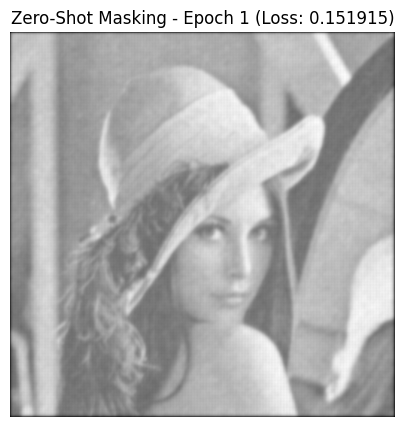

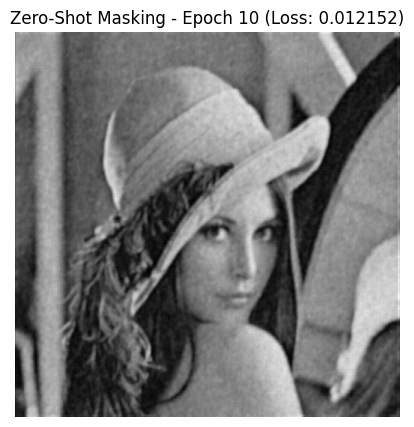

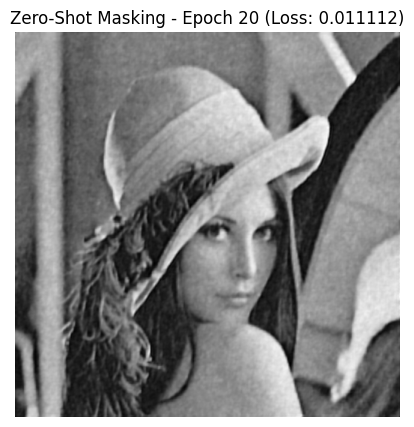

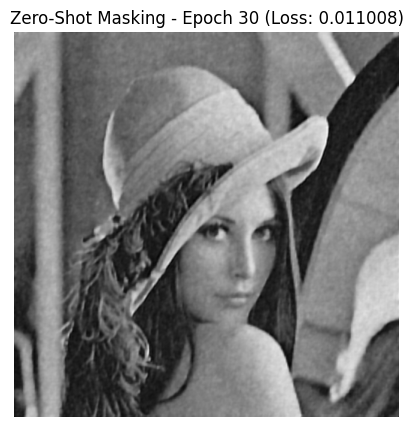

In [11]:
# NOISE2VOID STEP 2 & 3: TRAINING WITH BLIND-SPOT MASKED LOSS
#
# Core Idea:
# We pass the masked inputs through the U-Net. Crucially, we compute the loss ONLY
# at the masked pixel locations. Since the noise is spatially independent (uncorrelated),
# the network cannot predict the noise of the masked pixel, but it can predict the
# underlying clean signal. Thus, minimizing MSE on masked pixels leads to denoising.

# Initialize the model for zero-shot training
denoiser_zeroshot = Unet(in_channels=1, out_channels=1).to(device)
optimizer_zs = optim.Adam(denoiser_zeroshot.parameters(), lr=0.001)

epochs_zs = 30
zs_losses = []

# Create a dataset using only noisy_source tiles
tile_dataset_zs = TensorDataset(tiles_source_tensor, tiles_source_tensor)
tile_loader_zs = DataLoader(tile_dataset_zs, batch_size=32, shuffle=True)

for epoch in range(1, epochs_zs + 1):
    denoiser_zeroshot.train()
    epoch_loss = 0.0

    for batch, _ in tile_loader_zs:
        batch = batch.to(device)

        # Step 1: Generate blind-spots by masking inputs
        masked_batch, masks = create_masked_batch(batch, mask_ratio=0.10)
        masked_batch = masked_batch.to(device)
        masks = masks.to(device)

        optimizer_zs.zero_grad()

        # Step 2: Forward pass on masked batch
        output = denoiser_zeroshot(masked_batch)

        # Step 3: Compute reconstruction loss strictly at the masked positions
        loss = torch.sum(((output - batch) * masks) ** 2) / torch.sum(masks)
        loss.backward()
        optimizer_zs.step()

        epoch_loss += loss.item() * batch.size(0)

    epoch_loss /= len(tile_loader_zs.dataset)
    zs_losses.append(epoch_loss)

    # Display reconstruction progress
    if epoch % 1 == 0 or epoch == 1:
        denoiser_zeroshot.eval()
        with torch.no_grad():
            current_output = denoiser_zeroshot(fixed_noisy_input).cpu()
        current_img = torch.clamp(current_output.squeeze(), 0.0, 1.0).numpy()

        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(current_img, cmap='gray')
        ax.set_title(f'Zero-Shot Masking - Epoch {epoch} (Loss: {epoch_loss:.6f})')
        ax.axis('off')
        plt.show()

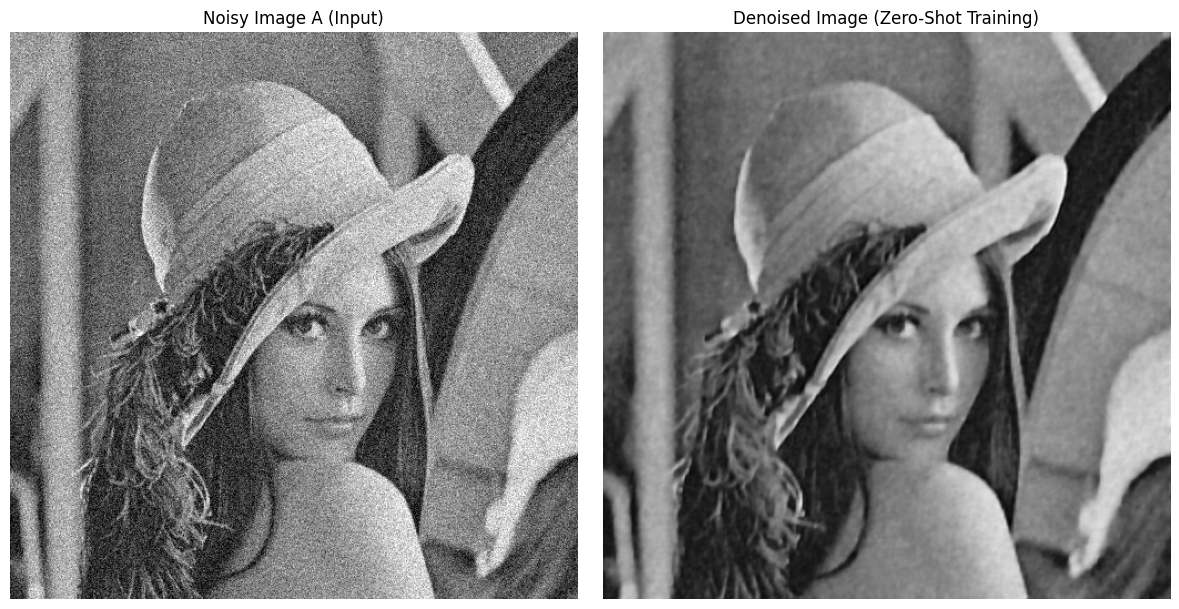

In [15]:
# Evaluate and display zero-shot denoising performance
denoiser_zeroshot.eval()
with torch.no_grad():
    output_tensor_zs = denoiser_zeroshot(fixed_noisy_input).cpu()

denoised_zs_np = torch.clamp(output_tensor_zs.squeeze(), 0.0, 1.0).numpy()
denoised_image_scaled_zs = (denoised_zs_np * 255.0).astype(np.uint8)

# Save the zero-shot denoised image
output_path_zs = "denoised_lena_zeroshot.png"
saved_image_zs = Image.fromarray(denoised_image_scaled_zs)
saved_image_zs.save(output_path_zs)

# Display visual comparisons
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(noisy, cmap='gray')
axes[0].set_title('Noisy Image A (Input)')
axes[0].axis('off')

axes[1].imshow(denoised_image_scaled_zs, cmap='gray')
axes[1].set_title('Denoised Image (Zero-Shot Training)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [16]:
fig.savefig('unet_n2v_comparison.png', bbox_inches='tight', dpi=300)